In [91]:
# Import packages
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from scipy import stats

In [34]:
df_change_my_view = pd.read_csv('./data/data_full_story.csv')
df_change_my_view

,name,story_score,agency_score,event_score,world_score,suspense_score,surprise_score,curiosity_score
0,t1_c95k50u,0.000000,1.000000,1.000000,1.000000,2.75,2.25,1.75
1,t1_c95mz3n,0.857143,4.000000,5.000000,1.000000,2.75,2.75,3.25
2,t1_c95l4my,0.857143,4.000000,4.000000,1.000000,2.75,3.25,3.50
3,t1_c95mcms,0.857143,5.000000,5.000000,1.000000,3.25,4.00,2.50
4,t3_1aenyc,1.000000,5.000000,5.000000,3.666667,2.75,3.50,3.75
...,...,...,...,...,...,...,...,...
615,t1_cauc7tb,0.000000,1.000000,1.000000,1.000000,2.50,2.75,2.25
616,t1_caue431,0.000000,1.000000,1.000000,1.000000,1.00,1.50,1.50
617,t1_ck496qz,0.571429,2.666667,2.666667,1.000000,2.50,2.75,3.25
618,t1_chkfbo3,0.857143,5.000000,3.666667,3.333333,1.75,2.00,2.75


#### 2. Scatterplots of the Data

In [35]:
independent_variables = ['agency_score', 'event_score', 'world_score', 'suspense_score', 'surprise_score', 'curiosity_score']

In [81]:
def scatter(independent_variables):
    """
    Plots 6 scatter plots of the effect of the story features on the story score.

    Parameter:
        independent_variables: List of independent variables.
    Return:
        6 scatter plots.
    """
    row = 0
    col = 0
    # Loop over the independent variables
    for independent_variable in independent_variables:
        # Plot a scatter plot
        sns.scatterplot(x=independent_variable, y='story_score', data=df_change_my_view, ax=axes[row, col]).set_title(f'Effect of {re.sub('_', ' ', independent_variable).title()} on Story Score')

        # Check where the histogram is going to be plotted
        if col < 3:
            col += 1
        if (col == 3) and (row == 0):
            col = 0
            row = 1

    # Plot scatterplots
    plt.tight_layout()
    return plt.show()

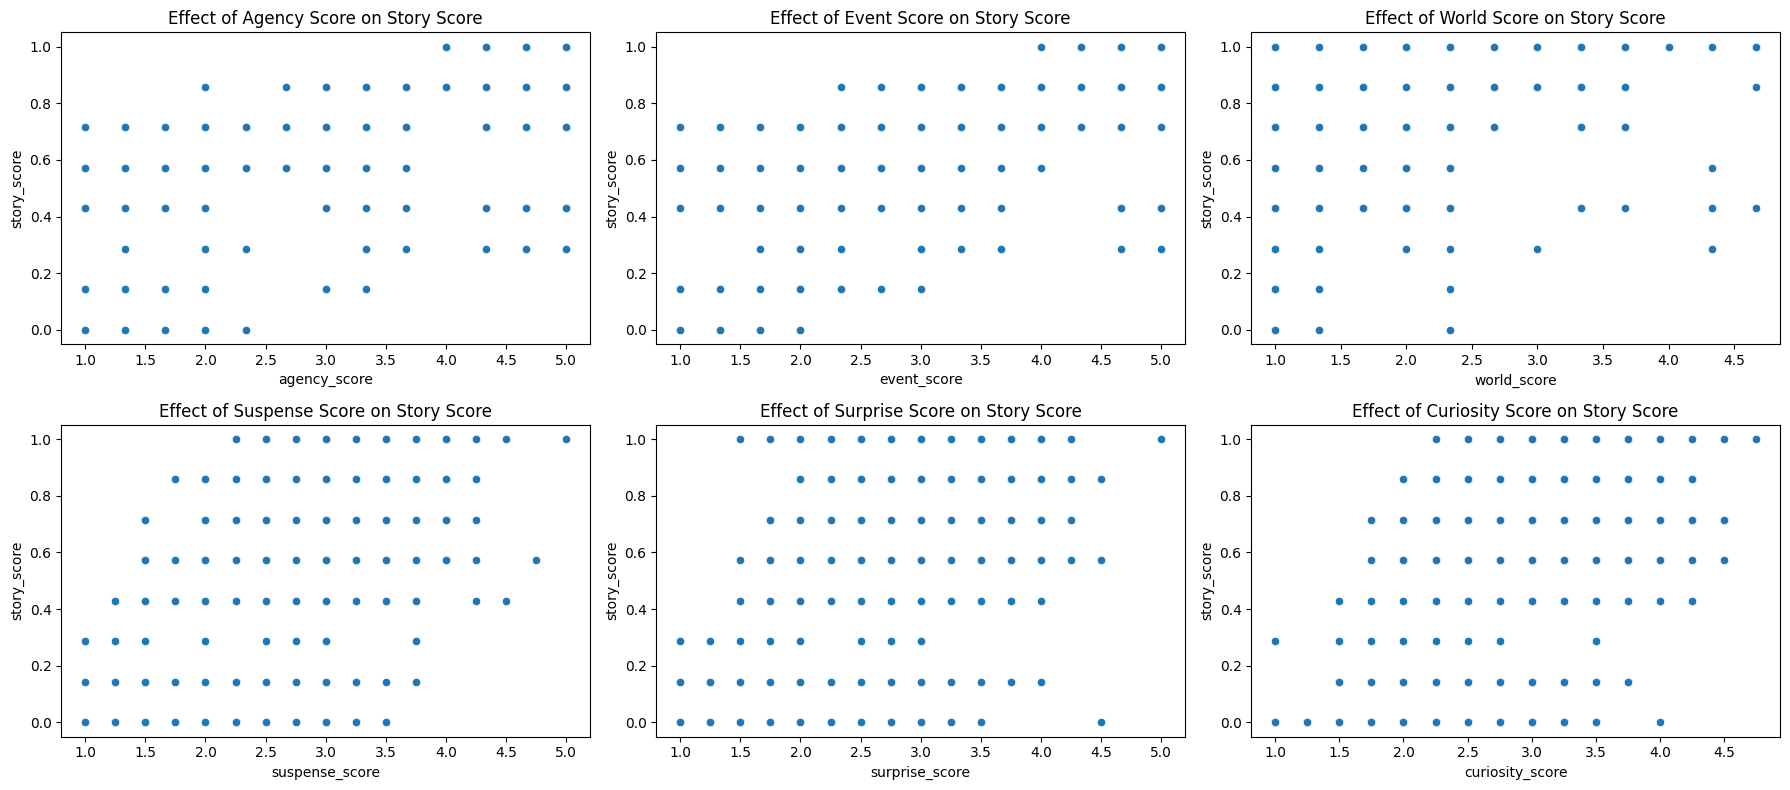

In [82]:
# Create 6 scatterplots
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
scatter(independent_variables)

### 3 - 7.

Simple Linear Regression

agency_score:
Intercept: 0.024369675050673445
Slope:     [0.18627994]


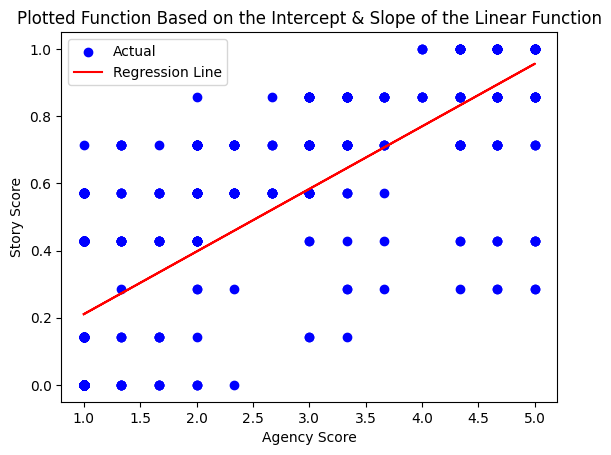

R-squared Score: 0.580823110283913


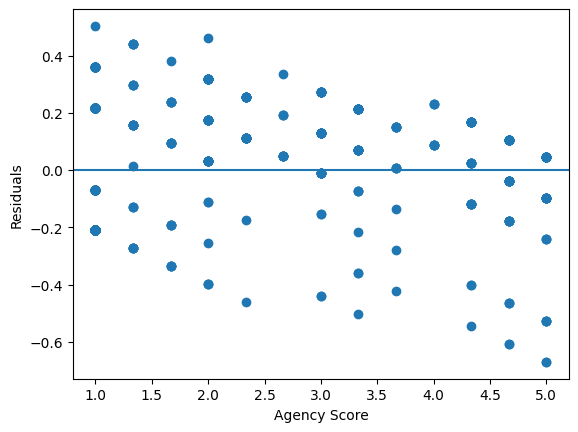

ShapiroResult(statistic=np.float64(0.9433870313864505), pvalue=np.float64(1.2397856766787579e-14))

event_score:
Intercept: 0.020186836862851998
Slope:     [0.19334794]


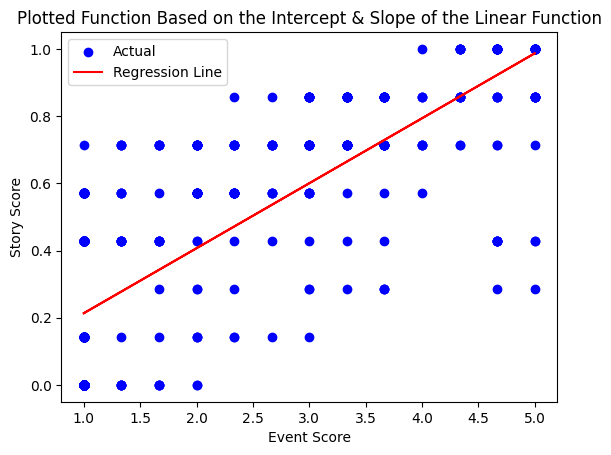

R-squared Score: 0.5971390119224571


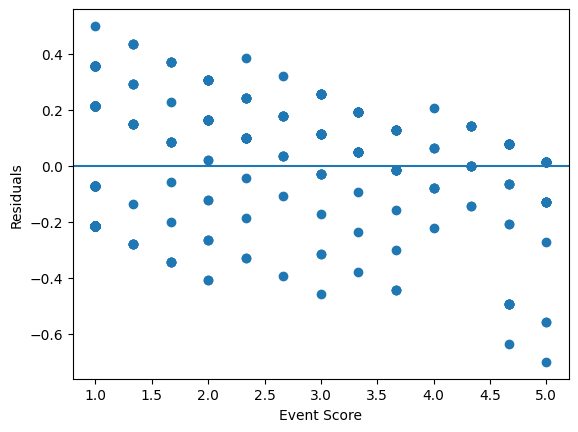

ShapiroResult(statistic=np.float64(0.9426995145578387), pvalue=np.float64(9.875589868181207e-15))

world_score:
Intercept: 0.14541022807542575
Slope:     [0.20197245]


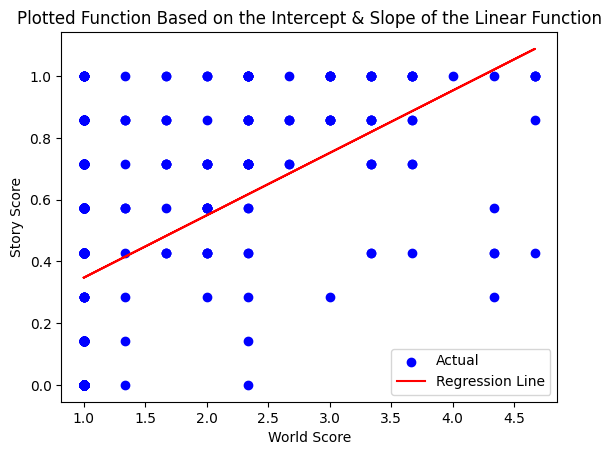

R-squared Score: 0.20441831933988508


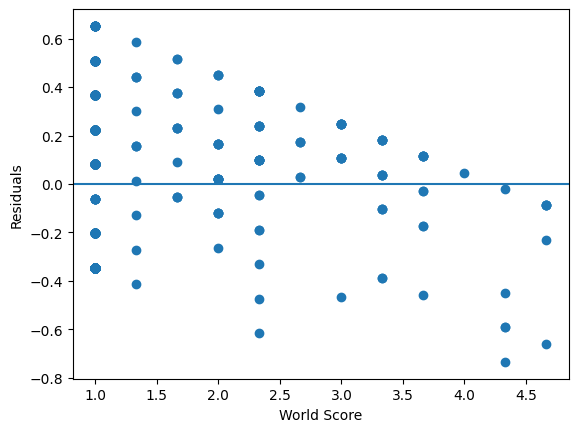

ShapiroResult(statistic=np.float64(0.9143422733035259), pvalue=np.float64(3.122520751934363e-18))

suspense_score:
Intercept: -0.21450119998638417
Slope:     [0.25757107]


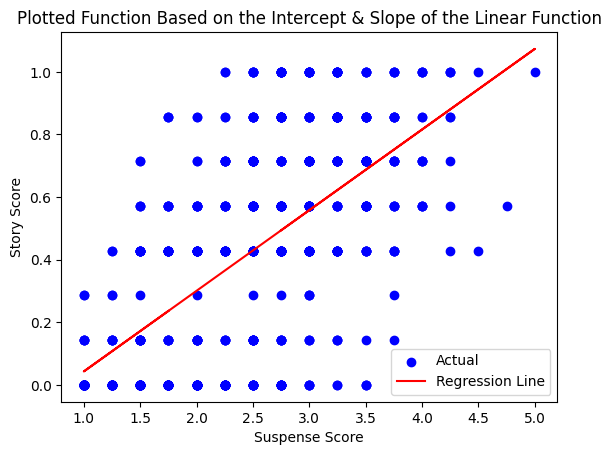

R-squared Score: 0.4214307264112034


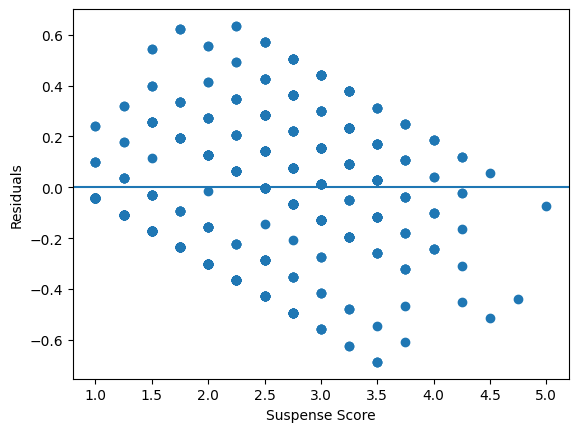

ShapiroResult(statistic=np.float64(0.994187025887173), pvalue=np.float64(0.017909134186808385))

surprise_score:
Intercept: -0.20140768303424395
Slope:     [0.23856646]


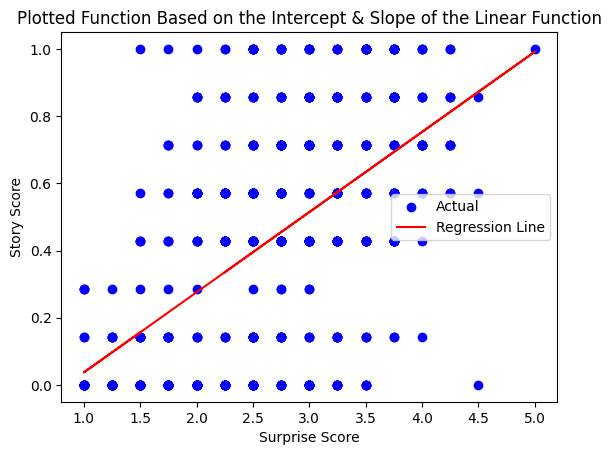

R-squared Score: 0.3427290841563504


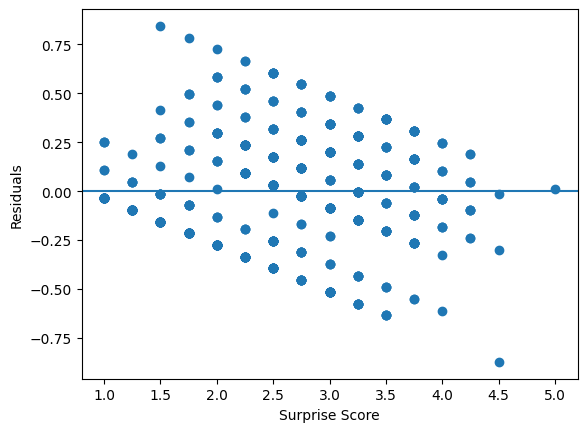

ShapiroResult(statistic=np.float64(0.9955295255509514), pvalue=np.float64(0.07191333447907214))

curiosity_score:
Intercept: -0.31947316124492453
Slope:     [0.26549191]


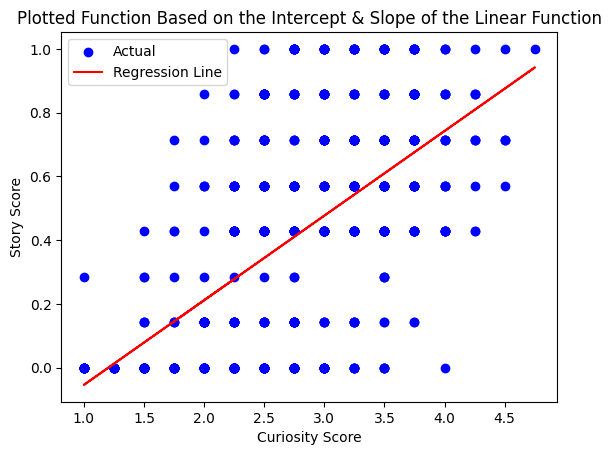

R-squared Score: 0.36142282050508


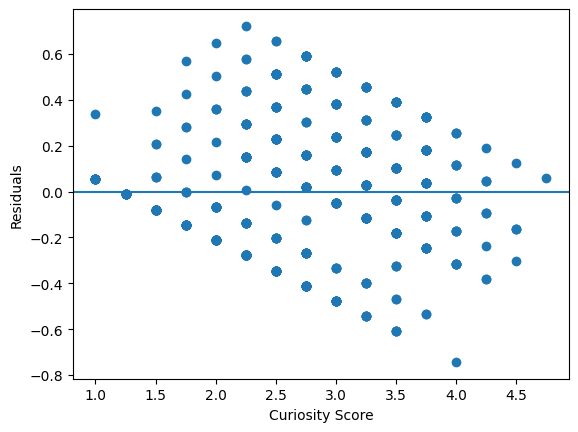

ShapiroResult(statistic=np.float64(0.9887298863187969), pvalue=np.float64(0.0001053884105024777))


In [ ]:
print("Simple Linear Regression")
for independent_variable in independent_variables:
    # Assign independent variable
    X = df_change_my_view[[independent_variable]]
    # Assign dependent variable
    y = df_change_my_view['story_score']

    # Create and fit a Linear Regression model
    lr = LinearRegression().fit(X, y)

    # Print the slope and intercept
    print(f"""\n{independent_variable}:
Intercept: {lr.intercept_}
Slope:     {lr.coef_}""")

    # Predict the story score for the test set
    y_pred = lr.predict(X)

    # Plot the function based on the intercept and slope
    plt.scatter(X, y, color='blue', label='Actual') # Plot the actual data points
    plt.plot(X, y_pred, color='red', label='Regression Line') # Plot the regression line
    plt.xlabel(re.sub('_', ' ', independent_variable).title())
    plt.ylabel('Story Score')
    plt.title('Plotted Function Based on the Intercept & Slope of the Linear Function')
    plt.legend()
    plt.show()
    
    # Calculate the r^2 score
    r2 = r2_score(y, y_pred)
    print(f"R-squared Score: {r2}")

    # Calculate the residuals
    res = y - y_pred

    # Plot the residuals
    plt.scatter(X, res)
    plt.axhline(y=0)
    plt.xlabel(re.sub('_', ' ', independent_variable).title())
    plt.ylabel("Residuals")
    plt.show()

    # Perform the Shapiro-Wilk test
    shapiro_test = stats.shapiro(res)
    print(shapiro_test)